<a href="https://colab.research.google.com/github/Bharath-2810/LSTM-/blob/main/website_traffic_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import pandas as pd
import numpy as np

# Check files in your current working directory
print(os.listdir())

['.config', 'sample_data']


In [4]:
import os

print("Current folder:", os.getcwd())
print("Files available:", os.listdir())

Current folder: /content
Files available: ['.config', 'sample_data']


In [6]:
from google.colab import files
uploaded = files.upload()

import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
display(df.head())
print(df.columns.tolist())

Saving validation_score.csv to validation_score.csv
Dataset shape: (145063, 18)


,Unnamed: 0,median7,median14,median21,median28,median35,median42,median49,median7_h,median14_h,median21_h,median28_h,median35_h,median42_h,median49_h,holiday,holiday_log,yearly_log
0,0,0.394786,0.398010,0.405826,0.405826,0.405826,0.405826,0.405826,0.489267,0.415286,0.405018,0.403895,0.405018,0.405018,0.403465,0.519470,0.424500,0.636273
1,1,0.415525,0.436615,0.484943,0.542946,0.484943,0.513212,0.503193,0.442488,0.432065,0.488515,0.539954,0.505501,0.507897,0.492611,0.748011,0.650149,0.409339
2,2,0.688429,0.500956,0.500956,0.492091,0.492091,0.492091,0.492091,0.531118,0.532642,0.500956,0.492091,0.497236,0.497236,0.497236,0.592786,0.527832,0.530204
3,3,0.356799,0.347737,0.356799,0.347737,0.356799,0.356799,0.356799,0.592931,0.340882,0.340882,0.340882,0.356799,0.356799,0.356799,0.486648,0.398567,0.346489
4,4,0.443860,0.453087,0.442593,0.489076,0.586340,0.586340,0.586340,0.475404,0.507502,0.485196,0.485196,0.573371,0.586340,0.586340,0.518994,0.496272,0.828707


['Unnamed: 0', 'median7', 'median14', 'median21', 'median28', 'median35', 'median42', 'median49', 'median7_h', 'median14_h', 'median21_h', 'median28_h', 'median35_h', 'median42_h', 'median49_h', 'holiday', 'holiday_log', 'yearly_log']


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.keras.utils.set_random_seed(42)

df = pd.read_csv("validation_score.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (145063, 18)

First five rows:


,Unnamed: 0,median7,median14,median21,median28,median35,median42,median49,median7_h,median14_h,median21_h,median28_h,median35_h,median42_h,median49_h,holiday,holiday_log,yearly_log
0,0,0.394786,0.398010,0.405826,0.405826,0.405826,0.405826,0.405826,0.489267,0.415286,0.405018,0.403895,0.405018,0.405018,0.403465,0.519470,0.424500,0.636273
1,1,0.415525,0.436615,0.484943,0.542946,0.484943,0.513212,0.503193,0.442488,0.432065,0.488515,0.539954,0.505501,0.507897,0.492611,0.748011,0.650149,0.409339
2,2,0.688429,0.500956,0.500956,0.492091,0.492091,0.492091,0.492091,0.531118,0.532642,0.500956,0.492091,0.497236,0.497236,0.497236,0.592786,0.527832,0.530204
3,3,0.356799,0.347737,0.356799,0.347737,0.356799,0.356799,0.356799,0.592931,0.340882,0.340882,0.340882,0.356799,0.356799,0.356799,0.486648,0.398567,0.346489
4,4,0.443860,0.453087,0.442593,0.489076,0.586340,0.586340,0.586340,0.475404,0.507502,0.485196,0.485196,0.573371,0.586340,0.586340,0.518994,0.496272,0.828707



Column names:
['Unnamed: 0', 'median7', 'median14', 'median21', 'median28', 'median35', 'median42', 'median49', 'median7_h', 'median14_h', 'median21_h', 'median28_h', 'median35_h', 'median42_h', 'median49_h', 'holiday', 'holiday_log', 'yearly_log']


In [8]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("Missing values:", df.isna().sum().sum())
print("Data types:")
print(df.dtypes)

Number of rows: 145063
Number of columns: 18
Missing values: 0
Data types:
Unnamed: 0       int64
median7        float64
median14       float64
median21       float64
median28       float64
median35       float64
median42       float64
median49       float64
median7_h      float64
median14_h     float64
median21_h     float64
median28_h     float64
median35_h     float64
median42_h     float64
median49_h     float64
holiday        float64
holiday_log    float64
yearly_log     float64
dtype: object


In [9]:
import pandas as pd

df = pd.read_csv("validation_score.csv")

print("Shape:", df.shape)

print("\nFirst 10 rows:")
print(df.head(10).to_string())

print("\nLast 10 rows:")
print(df.tail(10).to_string())

print("\nColumn names:")
print(df.columns.tolist())

print("\nStatistical summary:")
print(df.describe().T)

print("\nFirst column values:")
print(df["Unnamed: 0"].head(20).tolist())

print("\nDuplicate rows:", df.duplicated().sum())

Shape: (145063, 18)

First 10 rows:
   Unnamed: 0   median7  median14  median21  median28  median35  median42  median49  median7_h  median14_h  median21_h  median28_h  median35_h  median42_h  median49_h   holiday  holiday_log  yearly_log
0           0  0.394786  0.398010  0.405826  0.405826  0.405826  0.405826  0.405826   0.489267    0.415286    0.405018    0.403895    0.405018    0.405018    0.403465  0.519470     0.424500    0.636273
1           1  0.415525  0.436615  0.484943  0.542946  0.484943  0.513212  0.503193   0.442488    0.432065    0.488515    0.539954    0.505501    0.507897    0.492611  0.748011     0.650149    0.409339
2           2  0.688429  0.500956  0.500956  0.492091  0.492091  0.492091  0.492091   0.531118    0.532642    0.500956    0.492091    0.497236    0.497236    0.497236  0.592786     0.527832    0.530204
3           3  0.356799  0.347737  0.356799  0.347737  0.356799  0.356799  0.356799   0.592931    0.340882    0.340882    0.340882    0.356799    0.356799  

In [13]:
print("All columns:")
for col in df.columns:
    print(col)

print("\nCorrelation with yearly_log:")
print(df.corr(numeric_only=True)["yearly_log"].sort_values(
    ascending=False
))

All columns:
Unnamed: 0
median7
median14
median21
median28
median35
median42
median49
median7_h
median14_h
median21_h
median28_h
median35_h
median42_h
median49_h
holiday
holiday_log
yearly_log

Correlation with yearly_log:
yearly_log     1.000000
holiday_log    0.669905
median35_h     0.508575
median42_h     0.506038
median28_h     0.505859
median49_h     0.501272
median21_h     0.499217
median35       0.495653
median28       0.493630
median42       0.493503
median49       0.488805
median14_h     0.488400
median21       0.488157
median14       0.478809
median7_h      0.466943
median7        0.459923
holiday        0.436144
Unnamed: 0    -0.014487
Name: yearly_log, dtype: float64


In [14]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())

Shape: (145063, 18)
Columns: ['Unnamed: 0', 'median7', 'median14', 'median21', 'median28', 'median35', 'median42', 'median49', 'median7_h', 'median14_h', 'median21_h', 'median28_h', 'median35_h', 'median42_h', 'median49_h', 'holiday', 'holiday_log', 'yearly_log']
   Unnamed: 0   median7  median14  median21  median28  median35  median42  \
0           0  0.394786  0.398010  0.405826  0.405826  0.405826  0.405826   
1           1  0.415525  0.436615  0.484943  0.542946  0.484943  0.513212   
2           2  0.688429  0.500956  0.500956  0.492091  0.492091  0.492091   
3           3  0.356799  0.347737  0.356799  0.347737  0.356799  0.356799   
4           4  0.443860  0.453087  0.442593  0.489076  0.586340  0.586340   

   median49  median7_h  median14_h  median21_h  median28_h  median35_h  \
0  0.405826   0.489267    0.415286    0.405018    0.403895    0.405018   
1  0.503193   0.442488    0.432065    0.488515    0.539954    0.505501   
2  0.492091   0.531118    0.532642    0.500956    0

In [16]:
# Remove the index column from the feature data
data = df.drop(columns=["Unnamed: 0"], errors="ignore").copy()

# Check basic properties
print("Rows:", len(data))
print("Features:", data.shape[1])
print("Missing values:", data.isnull().sum().sum())

# Check whether rows are identical
print("Duplicate rows:", data.duplicated().sum())

# Check the value distribution of possible target
print(data["yearly_log"].describe())

Rows: 145063
Features: 17
Missing values: 0
Duplicate rows: 2325
count    145063.000000
mean          0.612651
std           0.428715
min           0.000000
25%           0.306678
50%           0.492578
75%           0.778328
max           2.000000
Name: yearly_log, dtype: float64


In [10]:

print(df.head())
print(df.columns.tolist())

   Unnamed: 0   median7  median14  median21  median28  median35  median42  \
0           0  0.394786  0.398010  0.405826  0.405826  0.405826  0.405826   
1           1  0.415525  0.436615  0.484943  0.542946  0.484943  0.513212   
2           2  0.688429  0.500956  0.500956  0.492091  0.492091  0.492091   
3           3  0.356799  0.347737  0.356799  0.347737  0.356799  0.356799   
4           4  0.443860  0.453087  0.442593  0.489076  0.586340  0.586340   

   median49  median7_h  median14_h  median21_h  median28_h  median35_h  \
0  0.405826   0.489267    0.415286    0.405018    0.403895    0.405018   
1  0.503193   0.442488    0.432065    0.488515    0.539954    0.505501   
2  0.492091   0.531118    0.532642    0.500956    0.492091    0.497236   
3  0.356799   0.592931    0.340882    0.340882    0.340882    0.356799   
4  0.586340   0.475404    0.507502    0.485196    0.485196    0.573371   

   median42_h  median49_h   holiday  holiday_log  yearly_log  
0    0.405018    0.403465  0.

In [11]:
print(df["Unnamed: 0"].head(20))

0      0
1      1
2      2
3      3
4      4
5      5
6      6
7      7
8      8
9      9
10    10
11    11
12    12
13    13
14    14
15    15
16    16
17    17
18    18
19    19
Name: Unnamed: 0, dtype: int64


In [12]:
print("Dataset filename:", "your_dataset.csv")
print("\nColumn data types:")
print(df.dtypes)

print("\nFeature value ranges:")
print(df.describe().round(3).T)

print("\nLast 10 rows:")
print(df.tail(10))

Dataset filename: your_dataset.csv

Column data types:
Unnamed: 0       int64
median7        float64
median14       float64
median21       float64
median28       float64
median35       float64
median42       float64
median49       float64
median7_h      float64
median14_h     float64
median21_h     float64
median28_h     float64
median35_h     float64
median42_h     float64
median49_h     float64
holiday        float64
holiday_log    float64
yearly_log     float64
dtype: object

Feature value ranges:
                count       mean        std    min        25%        50%  \
Unnamed: 0   145063.0  72531.000  41876.225  0.000  36265.500  72531.000   
median7      145063.0      0.473      0.312  0.000      0.259      0.398   
median14     145063.0      0.467      0.309  0.000      0.257      0.391   
median21     145063.0      0.466      0.308  0.000      0.258      0.391   
median28     145063.0      0.469      0.310  0.000      0.259      0.393   
median35     145063.0      0.471      

In [15]:
print(df.head(10).to_string())

   Unnamed: 0   median7  median14  median21  median28  median35  median42  median49  median7_h  median14_h  median21_h  median28_h  median35_h  median42_h  median49_h   holiday  holiday_log  yearly_log
0           0  0.394786  0.398010  0.405826  0.405826  0.405826  0.405826  0.405826   0.489267    0.415286    0.405018    0.403895    0.405018    0.405018    0.403465  0.519470     0.424500    0.636273
1           1  0.415525  0.436615  0.484943  0.542946  0.484943  0.513212  0.503193   0.442488    0.432065    0.488515    0.539954    0.505501    0.507897    0.492611  0.748011     0.650149    0.409339
2           2  0.688429  0.500956  0.500956  0.492091  0.492091  0.492091  0.492091   0.531118    0.532642    0.500956    0.492091    0.497236    0.497236    0.497236  0.592786     0.527832    0.530204
3           3  0.356799  0.347737  0.356799  0.347737  0.356799  0.356799  0.356799   0.592931    0.340882    0.340882    0.340882    0.356799    0.356799    0.356799  0.486648     0.398567   

In [17]:
import pandas as pd
import numpy as np

# Remove unnecessary index column
data = df.drop(columns=["Unnamed: 0"], errors="ignore").copy()

# Convert all columns to numeric
data = data.apply(pd.to_numeric, errors="coerce")

# Check missing values
print("Missing values before cleaning:")
print(data.isnull().sum().sum())

# Handle missing values if any
data = data.interpolate(limit_direction="both")
data = data.fillna(0)

# Remove duplicate rows
data = data.drop_duplicates().reset_index(drop=True)

print("\nShape after preprocessing:", data.shape)
print("Missing values:", data.isnull().sum().sum())
print("Duplicate rows:", data.duplicated().sum())

print("\nCleaned data:")
print(data.head())

Missing values before cleaning:
0

Shape after preprocessing: (142738, 17)
Missing values: 0
Duplicate rows: 0

Cleaned data:
    median7  median14  median21  median28  median35  median42  median49  \
0  0.394786  0.398010  0.405826  0.405826  0.405826  0.405826  0.405826   
1  0.415525  0.436615  0.484943  0.542946  0.484943  0.513212  0.503193   
2  0.688429  0.500956  0.500956  0.492091  0.492091  0.492091  0.492091   
3  0.356799  0.347737  0.356799  0.347737  0.356799  0.356799  0.356799   
4  0.443860  0.453087  0.442593  0.489076  0.586340  0.586340  0.586340   

   median7_h  median14_h  median21_h  median28_h  median35_h  median42_h  \
0   0.489267    0.415286    0.405018    0.403895    0.405018    0.405018   
1   0.442488    0.432065    0.488515    0.539954    0.505501    0.507897   
2   0.531118    0.532642    0.500956    0.492091    0.497236    0.497236   
3   0.592931    0.340882    0.340882    0.340882    0.356799    0.356799   
4   0.475404    0.507502    0.485196    0.4

In [18]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

scaled_data = scaler.fit_transform(data)

scaled_df = pd.DataFrame(
    scaled_data,
    columns=data.columns
)

print("Scaled data shape:", scaled_df.shape)
print(scaled_df.head())

Scaled data shape: (142738, 17)
    median7  median14  median21  median28  median35  median42  median49  \
0  0.197393  0.199005  0.202913  0.202913  0.202913  0.202913  0.202913   
1  0.207763  0.218307  0.242472  0.271473  0.242472  0.256606  0.251597   
2  0.344214  0.250478  0.250478  0.246045  0.246045  0.246045  0.246045   
3  0.178400  0.173868  0.178400  0.173868  0.178400  0.178400  0.178400   
4  0.221930  0.226543  0.221296  0.244538  0.293170  0.293170  0.293170   

   median7_h  median14_h  median21_h  median28_h  median35_h  median42_h  \
0   0.244633    0.207643    0.202509    0.201947    0.202509    0.202509   
1   0.221244    0.216032    0.244258    0.269977    0.252750    0.253949   
2   0.265559    0.266321    0.250478    0.246045    0.248618    0.248618   
3   0.296466    0.170441    0.170441    0.170441    0.178400    0.178400   
4   0.237702    0.253751    0.242598    0.242598    0.286686    0.293170   

   median49_h   holiday  holiday_log  yearly_log  
0    0.20

In [19]:
print("Minimum value:", scaled_df.min().min())
print("Maximum value:", scaled_df.max().max())

print("\nFinal dimensions:")
print("Rows:", scaled_df.shape[0])
print("Features:", scaled_df.shape[1])

Minimum value: 0.0
Maximum value: 1.0

Final dimensions:
Rows: 142738
Features: 17


In [20]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Use the cleaned data before scaling
# 'data' is your cleaned DataFrame
values = data.to_numpy(dtype=np.float32)

# Chronological 80/20 split
split_index = int(len(values) * 0.80)

# Fit scaler on training data only
scaler = MinMaxScaler()
scaler.fit(values[:split_index])

scaled_data = scaler.transform(values)

# Sequence settings
LOOKBACK = 30

X, y, target_indices = [], [], []

for i in range(LOOKBACK, len(scaled_data)):
    X.append(scaled_data[i - LOOKBACK:i])
    y.append(scaled_data[i])
    target_indices.append(i)

X = np.array(X, dtype=np.float32)
y = np.array(y, dtype=np.float32)
target_indices = np.array(target_indices)

# Chronological training and testing sets
train_mask = target_indices < split_index
test_mask = target_indices >= split_index

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (114160, 30, 17)
y_train: (114160, 17)
X_test: (28548, 30, 17)
y_test: (28548, 17)


In [22]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.random.set_seed(42)
np.random.seed(42)

# Build LSTM model
model = Sequential([
    LSTM(
        64,
        return_sequences=True,
        input_shape=(X_train.shape[1], X_train.shape[2])
    ),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(y_train.shape[1])
])

# Compile model
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

# Stop early if validation loss does not improve
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train the model: maximum 35 epochs
history = model.fit(
    X_train,
    y_train,
    epochs=15,       # Reduced from 35 to 15
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
3211/3211 ━━━━━━━━━━━━━━━━━━━━ 93s 28ms/step - loss: 0.0291 - mae: 0.1233 - val_loss: 0.0292 - val_mae: 0.1199
Epoch 2/15
3211/3211 ━━━━━━━━━━━━━━━━━━━━ 92s 29ms/step - loss: 0.0279 - mae: 0.1206 - val_loss: 0.0282 - val_mae: 0.1192
Epoch 3/15
3211/3211 ━━━━━━━━━━━━━━━━━━━━ 92s 29ms/step - loss: 0.0277 - mae: 0.1202 - val_loss: 0.0284 - val_mae: 0.1199
Epoch 4/15
3211/3211 ━━━━━━━━━━━━━━━━━━━━ 89s 28ms/step - loss: 0.0276 - mae: 0.1201 - val_loss: 0.0286 - val_mae: 0.1200
Epoch 5/15
3211/3211 ━━━━━━━━━━━━━━━━━━━━ 145s 29ms/step - loss: 0.0276 - mae: 0.1201 - val_loss: 0.0288 - val_mae: 0.1202
Epoch 6/15
3211/3211 ━━━━━━━━━━━━━━━━━━━━ 89s 28ms/step - loss: 0.0275 - mae: 0.1200 - val_loss: 0.0293 - val_mae: 0.1203
Epoch 7/15
3211/3211 ━━━━━━━━━━━━━━━━━━━━ 146s 29ms/step - loss: 0.0275 - mae: 0.1200 - val_loss: 0.0282 - val_mae: 0.1193


In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict test data
y_pred = model.predict(X_test, verbose=1)

print("Prediction shape:", y_pred.shape)
print("Actual shape:", y_test.shape)

893/893 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step
Prediction shape: (28548, 17)
Actual shape: (28548, 17)


In [25]:
# Calculate metrics for each feature
mae = mean_absolute_error(y_test, y_pred, multioutput="raw_values")

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred, multioutput="raw_values")
)

print("\nEvaluation Results:")

for i, col in enumerate(data.columns):
    print(f"{col}: MAE = {mae[i]:.4f}, RMSE = {rmse[i]:.4f}")

print("\nOverall MAE:", round(mae.mean(), 4))
print("Overall RMSE:", round(rmse.mean(), 4))


Evaluation Results:
median7: MAE = 0.0969, RMSE = 0.1398
median14: MAE = 0.0909, RMSE = 0.1299
median21: MAE = 0.0876, RMSE = 0.1248
median28: MAE = 0.0868, RMSE = 0.1236
median35: MAE = 0.0860, RMSE = 0.1227
median42: MAE = 0.0857, RMSE = 0.1224
median49: MAE = 0.0870, RMSE = 0.1251
median7_h: MAE = 0.1031, RMSE = 0.1456
median14_h: MAE = 0.0953, RMSE = 0.1344
median21_h: MAE = 0.0914, RMSE = 0.1288
median28_h: MAE = 0.0894, RMSE = 0.1259
median35_h: MAE = 0.0885, RMSE = 0.1253
median42_h: MAE = 0.0884, RMSE = 0.1252
median49_h: MAE = 0.0886, RMSE = 0.1260
holiday: MAE = 0.2178, RMSE = 0.2677
holiday_log: MAE = 0.1038, RMSE = 0.1481
yearly_log: MAE = 0.1130, RMSE = 0.1622

Overall MAE: 0.1
Overall RMSE: 0.1399


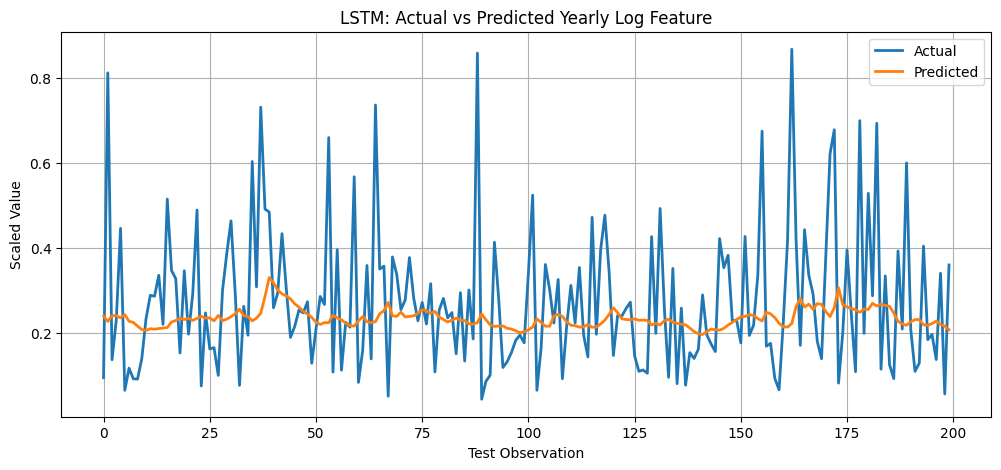

In [26]:
import matplotlib.pyplot as plt

feature_name = "yearly_log"
feature_index = data.columns.get_loc(feature_name)

# Plot the first 200 test observations
n = 200

plt.figure(figsize=(12, 5))

plt.plot(
    y_test[:n, feature_index],
    label="Actual",
    linewidth=2
)

plt.plot(
    y_pred[:n, feature_index],
    label="Predicted",
    linewidth=2
)

plt.title("LSTM: Actual vs Predicted Yearly Log Feature")
plt.xlabel("Test Observation")
plt.ylabel("Scaled Value")
plt.legend()
plt.grid(True)
plt.show()